# Renewable Integration with `difflow_power`

Adding a wind farm or a solar plant to a grid model raises three questions that
an ordinary dispatch study does not:

- **How much of it can the grid actually use?** Renewable output has (nearly)
  zero marginal cost, so the optimal power flow takes all of it until something
  stops it: a thermal unit at its minimum stable output, a line at its rating, a
  voltage limit. What is left over is *curtailed*.
- **What does the converter do to the reactive side?** An inverter is rated in
  MVA, a current limit. At full real output it has almost no var capability left;
  curtailed, it has its whole rating available as vars. That is a constraint
  coupling `P` and `Q`, `P² + Q² ≤ S²`, that box limits cannot express.
- **What is the resource worth?** What another m/s of wind, or another W/m² of
  sun, would save at the optimum. That is a derivative of the optimal cost, and
  in a differentiable model it is computed rather than estimated.

`difflow_power.renewables` provides resource models that turn weather into an
available MW, factories that build a curtailable generator inside its capability
circle, and a `curtailment` report that reads the value of resource off the
OPF multipliers. We will

1. look at the resource models and their derivatives,
2. sweep the wind speed on the WSCC 9-bus case through displacement, curtailment
   and a price collapse,
3. size an inverter for its var capability,
4. compute the value of wind in $/h per m/s and check it against re-solving,
5. run a day of wind and sun as a sequence of snapshots.

In [1]:
import jax
jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import difflow_power as dp

print(dp.cases.case9().summary())

case9 (WSCC 9-bus): 9 buses (1 slack, 2 PV, 6 PQ), 9 branches (0 transformers, 9 rated), 3 generators (820 MW capacity), 3 loads (315.0 MW + 115.0 MVAr), 1 loops, base 100 MVA


## 1. Resource models

Each model is a plain JAX function of the weather, so its derivative is one
`jax.grad` away.

**Wind.** The idealised turbine power curve: nothing below the cut-in speed;
between cut-in and rated speed the output follows the cube of the wind speed,
because the kinetic energy flux through the rotor goes as `ρv³`; pitch control
holds it at rating up to cut-out; above cut-out the turbine shuts down to
protect itself. The derivative is the cubic's slope in the middle region and
zero everywhere else, which matters later: in the flat region, more wind is
worth nothing to the turbine however valuable power is to the grid.

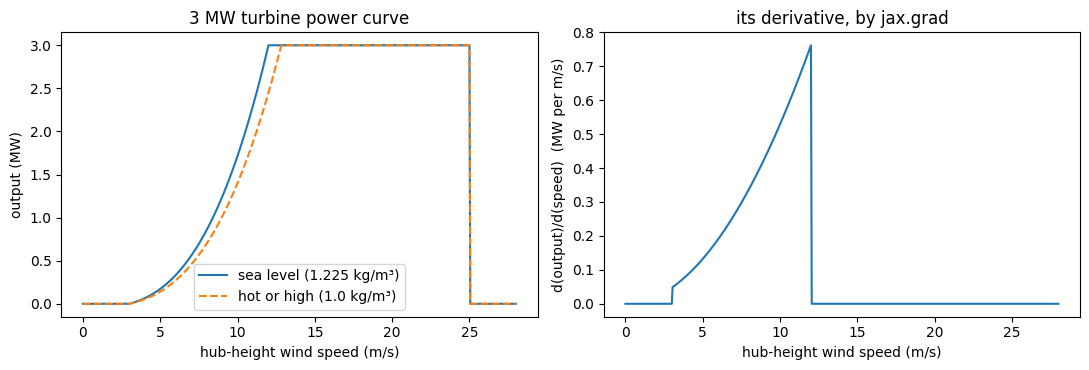

In [2]:
v = jnp.linspace(0.0, 28.0, 561)
turbine_mw = 3.0
power = dp.wind_turbine_power(v, turbine_mw)
slope = jax.vmap(jax.grad(lambda s: dp.wind_turbine_power(s, turbine_mw)))(v)
thin = dp.wind_turbine_power(v, turbine_mw, air_density=1.0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.plot(v, power, label="sea level (1.225 kg/m³)")
ax1.plot(v, thin, "--", label="hot or high (1.0 kg/m³)")
ax1.set_xlabel("hub-height wind speed (m/s)")
ax1.set_ylabel("output (MW)")
ax1.set_title("3 MW turbine power curve")
ax1.legend()
ax2.plot(v, slope)
ax2.set_xlabel("hub-height wind speed (m/s)")
ax2.set_ylabel("d(output)/d(speed)  (MW per m/s)")
ax2.set_title("its derivative, by jax.grad")
plt.tight_layout()
plt.show()

Thinner air reaches rating at a higher wind speed: density scales the cubic
region linearly.

**Solar.** `pv_power` follows PVWatts v5: DC output in proportion to irradiance
relative to 1000 W/m², falling by 0.47 % per °C of cell temperature above 25 °C
(the cell temperature from the NOCT model), 14 % lumped system losses, a 96 %
efficient inverter, and **clipping** at the inverter rating. Plants are routinely
built with more DC capacity than inverter (a DC/AC ratio of 1.1 to 1.3), trading
some output at noon on a clear day for more output the rest of the time.

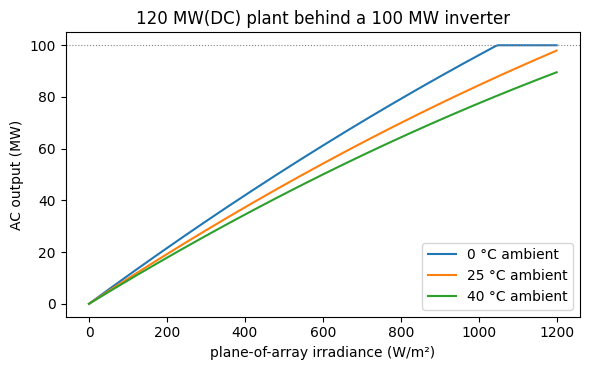

In [3]:
g = jnp.linspace(0.0, 1200.0, 241)
fig, ax = plt.subplots(figsize=(6, 3.8))
for t_amb in (0.0, 25.0, 40.0):
    ax.plot(g, dp.pv_power(g, t_amb, capacity_mw_dc=120.0, inverter_mw=100.0),
            label=f"{t_amb:.0f} °C ambient")
ax.axhline(100.0, color="grey", lw=0.8, ls=":")
ax.set_xlabel("plane-of-array irradiance (W/m²)")
ax.set_ylabel("AC output (MW)")
ax.set_title("120 MW(DC) plant behind a 100 MW inverter")
ax.legend()
plt.tight_layout()
plt.show()

A hot day costs output, and a cold clear one runs into the inverter ceiling.

## 2. A wind farm on the 9-bus case

Put a 300 MW wind farm (100 turbines of 3 MW) at bus 5, one of the three load
buses, and solve the AC optimal power flow across a range of wind speeds.
`wind_generator` evaluates the power curve and returns an ordinary
`Generator` with a floor of zero, a ceiling at the available power, zero cost and
an apparent-power rating equal to the nameplate. The OPF decides how much of it
to take.

The base case serves 315 MW. Each thermal unit has a 10 MW minimum stable
output, so no more than about 285 MW of wind can ever be absorbed, less once the
network has its say.

In [4]:
def with_wind(speed, n_turbines=100):
    net = dp.cases.case9()
    net.generators["wind"] = dp.wind_generator(
        "5", speed, n_turbines=n_turbines, turbine_mw=3.0)
    return net

speeds = np.arange(0.0, 16.01, 0.5)
sweep = []
for s in speeds:
    res = dp.solve_acopf(with_wind(float(s)))
    assert res.converged, s
    sweep.append((res, dp.curtailment(res, ["wind"])["wind"]))

print(f"{'m/s':>5} {'avail':>7} {'used':>7} {'curtail':>8} "
      f"{'cost $/h':>9} {'LMP@5':>7}  binding")
for s, (res, c) in zip(speeds, sweep):
    if s % 2 == 0 or 11.0 <= s <= 12.0:
        bind = [b for b in res.binding() if not b.startswith("vm_")]
        print(f"{s:5.1f} {c.available_mw:7.1f} {c.dispatched_mw:7.1f} "
              f"{c.curtailed_mw:8.2f} {res.cost:9.1f} "
              f"{res.lmp_mw['5']:7.2f}  {', '.join(bind)}")

  m/s   avail    used  curtail  cost $/h   LMP@5  binding


  0.0     0.0     0.0     0.00    5296.6   25.00  
  2.0     0.0     0.0     0.00    5296.6   25.00  


  4.0     6.5     6.5     0.00    5135.2   24.48  pg_wind_max
  6.0    33.3    33.3     0.00    4507.5   22.37  pg_wind_max
  8.0    85.5    85.5     0.00    3444.4   18.39  pg_wind_max
 10.0   171.6   171.6     0.00    2132.7   12.16  pg_wind_max
 11.0   230.0   230.0     0.00    1539.9    8.18  pg_wind_max


 11.5   263.5   263.5     0.00    1306.6    5.52  pg_g1_min, pg_wind_max
 12.0   300.0   292.7     7.35    1188.8    0.00  pg_g1_min, pg_g2_min, pg_g3_min


 14.0   300.0   292.7     7.35    1188.8    0.00  pg_g1_min, pg_g2_min, pg_g3_min
 16.0   300.0   292.7     7.35    1188.8    0.00  pg_g1_min, pg_g2_min, pg_g3_min


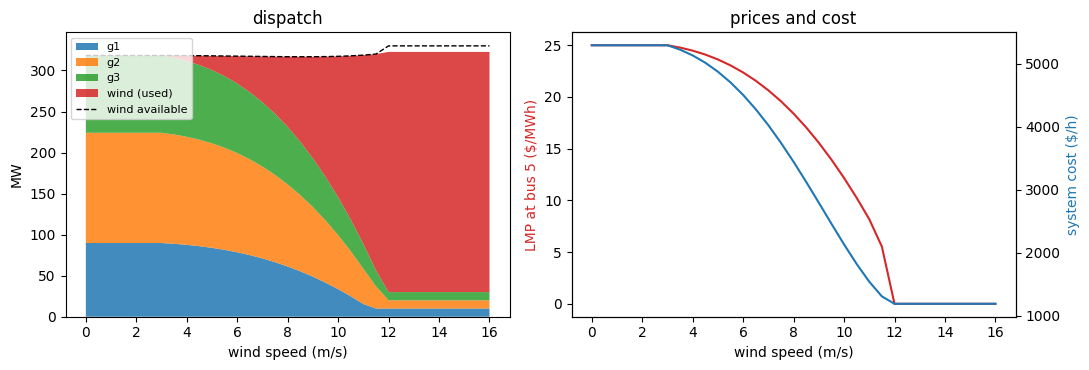

In [5]:
avail = np.array([c.available_mw for _, c in sweep])
used = np.array([c.dispatched_mw for _, c in sweep])
cost = np.array([r.cost for r, _ in sweep])
lmp5 = np.array([r.lmp_mw["5"] for r, _ in sweep])
thermal = {g: np.array([r.pg_mw[g] for r, _ in sweep]) for g in ("g1", "g2", "g3")}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.stackplot(speeds, thermal["g1"], thermal["g2"], thermal["g3"], used,
              labels=["g1", "g2", "g3", "wind (used)"], alpha=0.85)
ax1.plot(speeds, avail + sum(thermal.values()), "k--", lw=1,
         label="wind available")
ax1.set_xlabel("wind speed (m/s)")
ax1.set_ylabel("MW")
ax1.set_title("dispatch")
ax1.legend(loc="upper left", fontsize=8)
ax2.plot(speeds, lmp5, color="C3")
ax2.set_xlabel("wind speed (m/s)")
ax2.set_ylabel("LMP at bus 5 ($/MWh)", color="C3")
ax2b = ax2.twinx()
ax2b.plot(speeds, cost, color="C0")
ax2b.set_ylabel("system cost ($/h)", color="C0")
ax2.set_title("prices and cost")
plt.tight_layout()
plt.show()

Three regimes, all read off a single model:

- **Displacement** (below about 11.5 m/s). All the wind is used; the ceiling
  `pg_wind_max` binds. The expensive margin of each thermal unit is backed down
  and the price falls with it, from 25 $/MWh to about 5.5 at 11.5 m/s.
- **Curtailment** (above it). All three thermal units sit at their 10 MW floors
  (`pg_g*_min` binding) and the wind farm is told to spill the rest. The ceiling
  no longer binds, so the price of energy at every bus is **zero**: another MW of
  load would be served by curtailing less wind, which costs nothing. Zero and
  negative prices at high-renewable hours are what real markets see, and this is
  the mechanism.
- **Saturation** (above rated speed, 12 m/s). Nothing changes any more: the
  turbines are pitch-limited and already curtailed.

The farm's `value_per_mw`, the reduction in optimal cost per extra MW of
available wind, is the multiplier on its ceiling. For a zero-cost unit the
envelope theorem says this should equal the LMP at its bus while the ceiling
binds, and zero once it is curtailed:

In [6]:
value = np.array([c.value_per_mw for _, c in sweep])
print(f"{'m/s':>5} {'value $/MWh':>12} {'LMP@5 $/MWh':>12}")
for s, val, l in zip(speeds, value, lmp5):
    if s % 2 == 0:
        print(f"{s:5.1f} {val:12.3f} {l:12.3f}")

  m/s  value $/MWh  LMP@5 $/MWh
  0.0       24.995       24.995
  2.0       24.995       24.995
  4.0       24.475       24.475
  6.0       22.366       22.366
  8.0       18.387       18.387
 10.0       12.165       12.165
 12.0        0.000        0.000
 14.0        0.000        0.000
 16.0        0.000        0.000


They agree to the solver tolerance in every regime, and they come from different
places: one from the multiplier on a box bound, the other from the multiplier on
a bus balance.

## 3. Sizing an inverter for vars

The farm above never needed its reactive range: the three synchronous machines
supply the case's vars and the capability circle hardly binds. Load the case up
by 40 % and put a 100 MW solar plant at bus 9, running flat out, and the circle
starts to matter. With the inverter rated exactly at 100 MVA the plant is on the
circle at `Q ≈ 0`, so it can deliver vars only by giving up watts. Oversize the
inverter and it supplies vars for free, up to the point where the grid no longer
wants them.

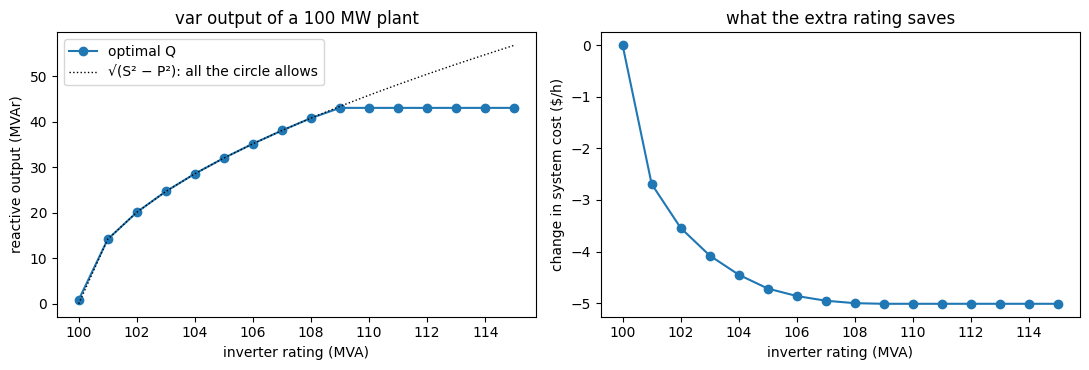

saving from 100 → 115 MVA: 5.01 $/h


In [7]:
ratings = np.linspace(100.0, 115.0, 16)
cap_rows = []
for s_max in ratings:
    net = dp.cases.case9().scaled_load(1.4)
    net.generators["pv"] = dp.renewable_generator("9", 100.0, float(s_max))
    res = dp.solve_acopf(net)
    assert res.converged
    k = res.layout.generators.index("pv")
    shadow = res.binding().get(f"capability_{k}", 0.0)
    cap_rows.append((res.cost, res.pg_mw["pv"], res.qg_mvar["pv"], shadow))
cap = np.array(cap_rows)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.plot(ratings, cap[:, 2], "o-", label="optimal Q")
ax1.plot(ratings, np.sqrt(ratings**2 - 100.0**2), "k:", lw=1,
         label="√(S² − P²): all the circle allows")
ax1.set_xlabel("inverter rating (MVA)")
ax1.set_ylabel("reactive output (MVAr)")
ax1.legend()
ax1.set_title("var output of a 100 MW plant")
ax2.plot(ratings, cap[:, 0] - cap[0, 0], "o-")
ax2.set_xlabel("inverter rating (MVA)")
ax2.set_ylabel("change in system cost ($/h)")
ax2.set_title("what the extra rating saves")
plt.tight_layout()
plt.show()
print(f"saving from 100 → 115 MVA: {cap[0, 0] - cap[-1, 0]:.2f} $/h")

Up to about 109 MVA the plant uses every var the circle allows and each MVA of
rating lowers the cost; past that the grid wants no more vars from bus 9 and the
circle stops binding. On this small, strong case the saving is a few dollars an
hour because the synchronous machines carry the reactive load anyway. On a weak
feeder, or a grid where inverters have displaced the machines, the same
calculation is what sizes the inverter.

## 4. What is the wind worth?

The value of a m/s of wind is a chain rule with two links:

$$
\frac{d\,\text{cost}^*}{dv} \;=\;
\underbrace{\frac{d\,\text{cost}^*}{dP^{max}}}_{-\,\text{value\_per\_mw}}
\;\cdot\;
\underbrace{\frac{dP^{max}}{dv}}_{\texttt{jax.grad}\text{ of the power curve}}
$$

The first comes from the OPF multipliers (the envelope theorem: no re-solve), the
second from differentiating the resource model. Check the product against a
finite difference of the optimal cost along the sweep:

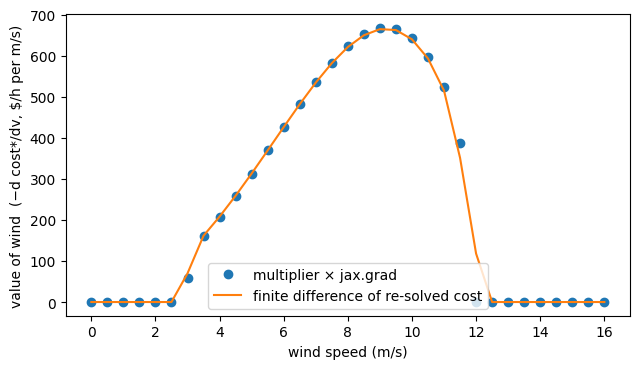

 6.0 m/s:    426.0 $/h per m/s (central difference    425.8)
 8.0 m/s:    622.6 $/h per m/s (central difference    620.8)
10.0 m/s:    643.6 $/h per m/s (central difference    639.6)


In [8]:
farm_curve = lambda s: 100 * dp.wind_turbine_power(s, 3.0)
dpmax_dv = np.array(jax.vmap(jax.grad(farm_curve))(jnp.asarray(speeds)))
analytic = -value * dpmax_dv                       # $/h per m/s
finite = np.gradient(cost, speeds)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(speeds, -analytic, "o", label="multiplier × jax.grad")
ax.plot(speeds, -finite, "-", label="finite difference of re-solved cost")
ax.set_xlabel("wind speed (m/s)")
ax.set_ylabel("value of wind  (−d cost*/dv, $/h per m/s)")
ax.legend()
plt.tight_layout()
plt.show()

for s in (6.0, 8.0, 10.0):
    i = int(np.argmin(abs(speeds - s)))
    print(f"{s:4.1f} m/s: {-analytic[i]:8.1f} $/h per m/s "
          f"(central difference {-finite[i]:8.1f})")

The two agree wherever the cost is smooth. The central difference is a coarse
check, with a 0.5 m/s step on a curve whose slope changes quickly; the
multiplier-based value is exact at each point and costs nothing beyond the
solve. Wind is worth the most around 9 m/s, where the power curve is steep and
energy is still priced above zero. Below cut-in more wind does nothing to a
stationary turbine, and in the curtailed regime it is worth nothing to the grid.

## 5. A day as a sequence of snapshots

Integration studies run the OPF hour by hour over a weather profile. Here a
180 MW wind farm at bus 5 sees a wind that is strongest before dawn and weakest
in the afternoon, and a 360 MW(DC) solar plant behind a 300 MW inverter at bus 9
sees a clear-sky irradiance curve, with load following a typical daily shape
(a morning shoulder and an evening peak).

Each hour is an independent snapshot. Nothing links one hour to the next: no
storage, no ramp limits, no reservoir budget. Those need a multi-period OPF,
which this plugin does not have.

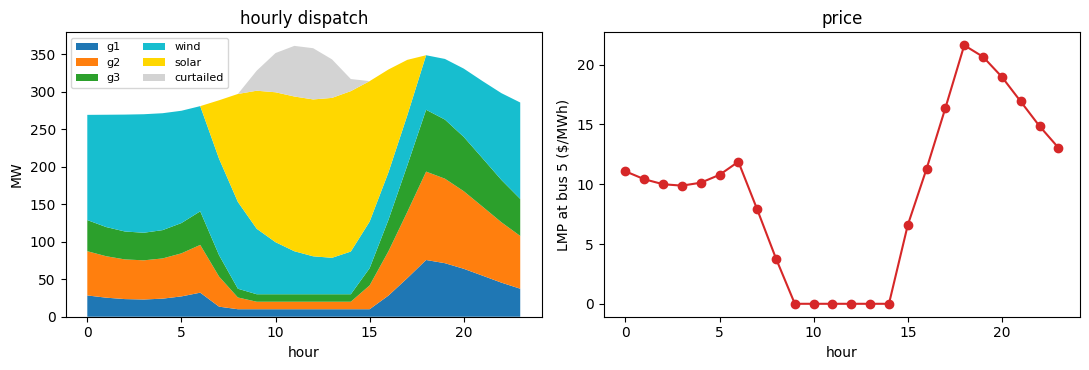

renewable share of energy: 59.9 %
energy curtailed:          282.5 MWh (6.2 % of available)
cost of the day:           49,118 $
thermal output 14:00 → 18:00: 30 → 276 MW


In [9]:
hours = np.arange(24)
wind_speed = 10.0 + 1.5 * np.cos(2 * np.pi * (hours - 3) / 24)     # m/s
irradiance = np.clip(1000.0 * np.sin(np.pi * (hours - 6) / 12), 0.0, None)
t_ambient = 18.0 + 8.0 * np.sin(np.pi * (hours - 9) / 12)
load_scale = 0.85 + 0.25 * np.exp(-((hours - 18) / 4.0) ** 2) \
                  + 0.10 * np.exp(-((hours - 9) / 3.0) ** 2)

day = []
for h in hours:
    net = dp.cases.case9().scaled_load(float(load_scale[h]))
    net.generators["wind"] = dp.wind_generator(
        "5", float(wind_speed[h]), n_turbines=60, turbine_mw=3.0)
    net.generators["solar"] = dp.solar_generator(
        "9", float(irradiance[h]), float(t_ambient[h]), capacity_mw_dc=360.0)
    res = dp.solve_acopf(net)
    assert res.converged, h
    cur = dp.curtailment(res, ["wind", "solar"])
    day.append((res, cur))

pg = {g: np.array([r.pg_mw[g] for r, _ in day])
      for g in ("g1", "g2", "g3", "wind", "solar")}
spilled = np.array([c["wind"].curtailed_mw + c["solar"].curtailed_mw
                    for _, c in day])
price = np.array([r.lmp_mw["5"] for r, _ in day])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.stackplot(hours, pg["g1"], pg["g2"], pg["g3"], pg["wind"], pg["solar"],
              spilled, labels=["g1", "g2", "g3", "wind", "solar", "curtailed"],
              colors=["C0", "C1", "C2", "C9", "gold", "lightgrey"])
ax1.set_xlabel("hour")
ax1.set_ylabel("MW")
ax1.set_title("hourly dispatch")
ax1.legend(loc="upper left", fontsize=8, ncol=2)
ax2.plot(hours, price, "o-", color="C3")
ax2.set_xlabel("hour")
ax2.set_ylabel("LMP at bus 5 ($/MWh)")
ax2.set_title("price")
plt.tight_layout()
plt.show()

renewable = pg["wind"].sum() + pg["solar"].sum()
total = sum(pg[g].sum() for g in pg)
print(f"renewable share of energy: {100 * renewable / total:.1f} %")
print(f"energy curtailed:          {spilled.sum():.1f} MWh "
      f"({100 * spilled.sum() / (renewable + spilled.sum()):.1f} % of available)")
print(f"cost of the day:           {sum(r.cost for r, _ in day):,.0f} $")
thermal_out = pg["g1"] + pg["g2"] + pg["g3"]
print(f"thermal output 14:00 → 18:00: {thermal_out[14]:.0f} → {thermal_out[18]:.0f} MW")

From about 09:00 to 14:00 the solar peak on top of the wind exceeds what the
system can absorb: all three thermal units sit at their 10 MW floors, the excess
is curtailed, and the price at bus 5 is zero. The evening peak then arrives as
the sun sets, the "duck curve" shape, and the thermal units ramp from their
floors to several times that output in four hours. A battery would move the curtailed midday energy
into that evening ramp, but deciding that needs the hours coupled together,
which is the multi-period problem this snapshot model deliberately leaves out.

## Summary

- A renewable unit is an ordinary `Generator` with a ceiling set by the weather,
  a floor of zero, and an apparent-power rating `s_max_mva` that the OPF poses as
  the capability circle `P² + Q² ≤ S²`.
- The resource models (`wind_turbine_power`, `pv_power`, `hydro_power`) are JAX
  functions, so their weather derivatives come from `jax.grad`.
- `curtailment` reports the curtailed MW and the marginal value of more
  resource, read from the OPF multipliers. Chained with the resource model's
  derivative, it gives the value of the weather itself, and it matches
  re-solving.
- Each solve is one snapshot. Storage, ramping and reservoir scheduling need
  time-coupled constraints that are not in this plugin.

See the *Renewable generators* section of the power documentation
(`docs/unit-operations-power.md`) for the API.